In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

In [2]:
df = pd.read_csv('../data/processed/preprocessed_data.csv')

print("Data loaded")
print("Shape:", df.shape)

Data loaded
Shape: (938599, 15)


In [3]:
#Prepare Features for Clustering
# Clustering- orbital features only
# Labels (pha, neo, class)  no use 

cluster_features = ['a_log', 'e_log', 'i_log', 'q_log', 'n_log', 'om', 'w', 'ma']

X = df[cluster_features]
y_pha = df['pha_encoded']

print("Clustering features:", X.shape)
print("Features:", cluster_features)

Clustering features: (938599, 8)
Features: ['a_log', 'e_log', 'i_log', 'q_log', 'n_log', 'om', 'w', 'ma']


In [4]:
# 50,000 sampple  use
np.random.seed(42)
sample_idx = np.random.choice(len(X), 5000, replace=False)

X_sample = X.iloc[sample_idx].values
y_pha_sample = y_pha.iloc[sample_idx].values

print("Sample shape:", X_sample.shape)

Sample shape: (5000, 8)


In [5]:
scaler_cluster = StandardScaler()
X_scaled = scaler_cluster.fit_transform(X_sample)

print("Scaling done")

Scaling done


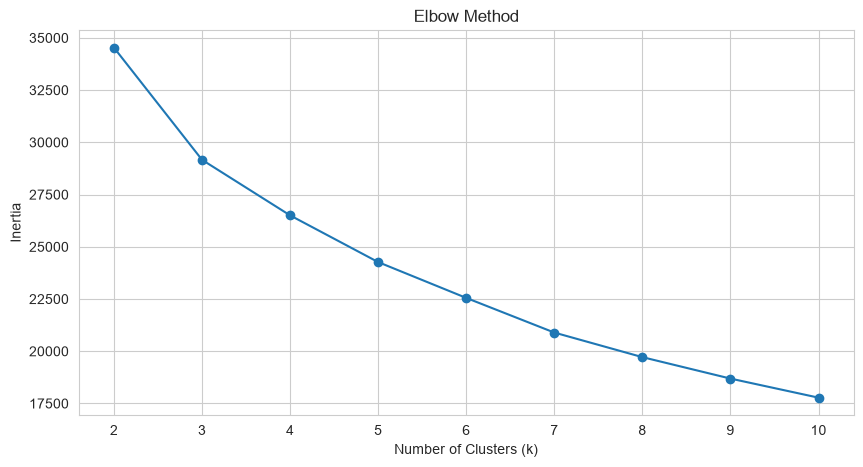

In [6]:
#k means elbow method

inertia = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(K_range, inertia, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

k=2: Silhouette = 0.1409
k=3: Silhouette = 0.1464
k=4: Silhouette = 0.1311
k=5: Silhouette = 0.1290
k=6: Silhouette = 0.1310
k=7: Silhouette = 0.1349
k=8: Silhouette = 0.1356
k=9: Silhouette = 0.1376
k=10: Silhouette = 0.1384


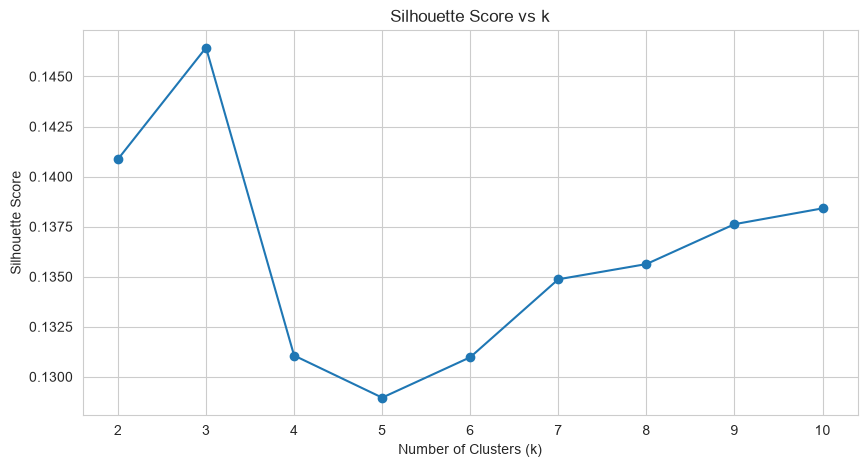

In [7]:
# k means silhouette score

# Fast silhouette - use 5000 samples
sil_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    
    # Use only 3000 samples for silhouette (faster)
    score = silhouette_score(X_scaled, labels, sample_size=3000, random_state=42)
    sil_scores.append(score)
    print(f"k={k}: Silhouette = {score:.4f}")

plt.figure(figsize=(10, 5))
plt.plot(K_range, sil_scores, marker='o')
plt.title('Silhouette Score vs k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

In [8]:
# k means final model # Best k select (highest silhouette)
best_k = K_range[np.argmax(sil_scores)]
print("Best k:", best_k)

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-Means Silhouette:", 
      silhouette_score(X_scaled, kmeans_labels, sample_size=3000, random_state=42))

Best k: 3
K-Means Silhouette: 0.1464383511307889


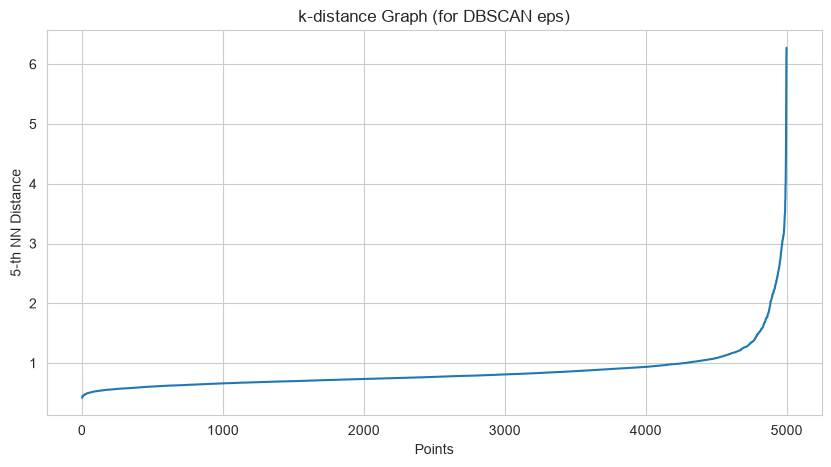

In [9]:
#DBSCAN — k-distance Graph

k = 5
neighbors = NearestNeighbors(n_neighbors=k)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

distances = np.sort(distances[:, k-1], axis=0)

plt.figure(figsize=(10, 5))
plt.plot(distances)
plt.title('k-distance Graph (for DBSCAN eps)')
plt.xlabel('Points')
plt.ylabel(f'{k}-th NN Distance')
plt.grid(True)
plt.show()

In [10]:
#DBSCAN — Tune eps

eps_values = [0.3, 0.5, 0.7, 1.0]
min_samples = 5

dbscan_results = []

for eps in eps_values:
    dbscan = DBSCAN(eps=eps, min_samples=min_samples)
    labels = dbscan.fit_predict(X_scaled)
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = (labels == -1).sum()
    
    if n_clusters > 1:
        sil = silhouette_score(X_scaled, labels, sample_size=3000, random_state=42)
    else:
        sil = -1
    
    dbscan_results.append({
        'eps': eps, 'n_clusters': n_clusters, 
        'n_noise': n_noise, 'silhouette': sil
    })
    
    print(f"eps={eps}: clusters={n_clusters}, noise={n_noise}, sil={sil:.4f}")

dbscan_df = pd.DataFrame(dbscan_results)
print("\n", dbscan_df)

eps=0.3: clusters=0, noise=5000, sil=-1.0000
eps=0.5: clusters=25, noise=4839, sil=-0.4968
eps=0.7: clusters=60, noise=2263, sil=-0.4520
eps=1.0: clusters=4, noise=394, sil=0.1640

    eps  n_clusters  n_noise  silhouette
0  0.3           0     5000   -1.000000
1  0.5          25     4839   -0.496833
2  0.7          60     2263   -0.451968
3  1.0           4      394    0.163984


In [11]:
best_eps = dbscan_df.loc[dbscan_df['silhouette'].idxmax(), 'eps']
print("Best eps:", best_eps)

dbscan = DBSCAN(eps=best_eps, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
print("DBSCAN clusters:", n_clusters)
print("Noise points:", (dbscan_labels == -1).sum())

if n_clusters > 1:
    print("DBSCAN Silhouette:", 
          silhouette_score(X_scaled, dbscan_labels, sample_size=3000, random_state=42))

Best eps: 1.0
DBSCAN clusters: 4
Noise points: 394
DBSCAN Silhouette: 0.163983823545732


In [12]:
#Compare K-Means vs DBSCAN

comparison = pd.DataFrame({
    'Method': ['K-Means', 'DBSCAN'],
    'Best Param': [f'k={best_k}', f'eps={best_eps}'],
    'N Clusters': [best_k, n_clusters],
    'Silhouette': [
        silhouette_score(X_scaled, kmeans_labels, sample_size=3000, random_state=42),
        silhouette_score(X_scaled, dbscan_labels, sample_size=3000, random_state=42) if n_clusters > 1 else -1
    ]
})

print(comparison)

    Method Best Param  N Clusters  Silhouette
0  K-Means        k=3           3    0.146438
1   DBSCAN    eps=1.0           4    0.163984


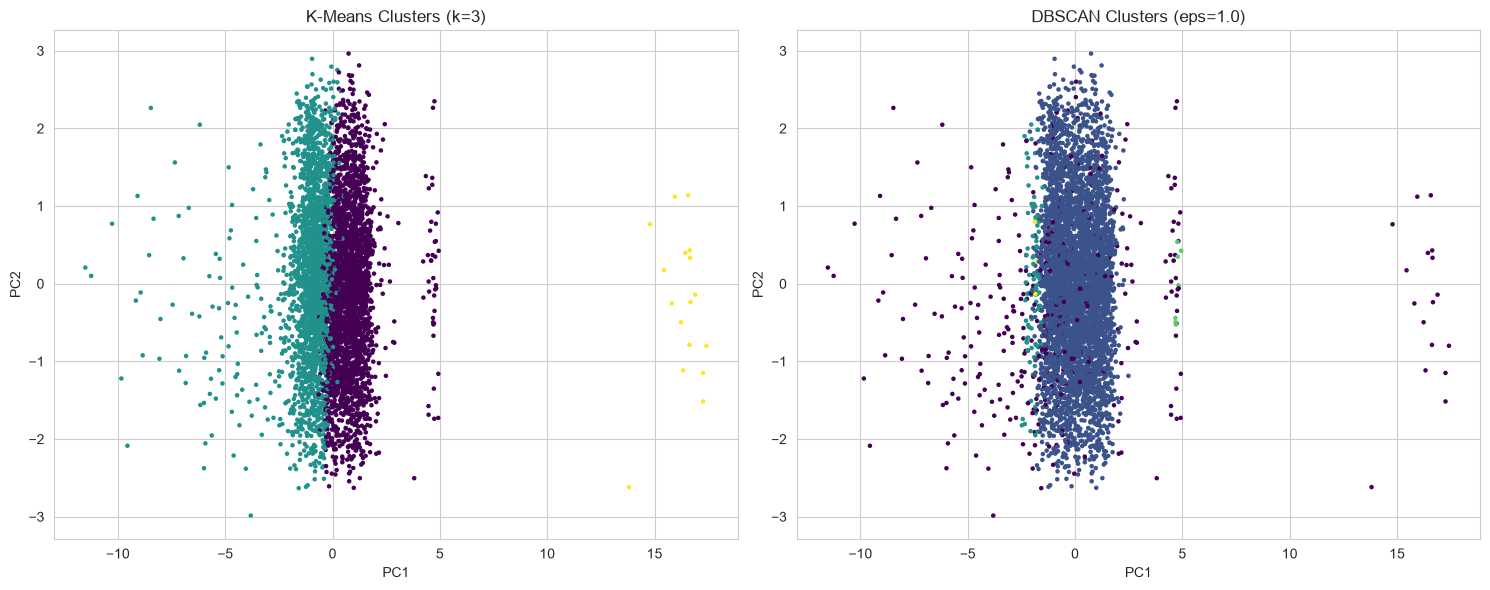

In [13]:
#Visualize Clusters (PCA)

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis', s=5)
axes[0].set_title(f'K-Means Clusters (k={best_k})')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, cmap='viridis', s=5)
axes[1].set_title(f'DBSCAN Clusters (eps={best_eps})')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

plt.tight_layout()
plt.show()

In [15]:
print("kmeans_labels shape:", kmeans_labels.shape)
print("y_pha_sample shape:", y_pha_sample.shape)

assert kmeans_labels.shape[0] == y_pha_sample.shape[0], "Shape mismatch!"
print("Shapes match!")

kmeans_labels shape: (5000,)
y_pha_sample shape: (5000,)
Shapes match!


In [16]:
# Clusters vs PHA Distribution
cluster_pha = pd.DataFrame({
    'cluster': kmeans_labels,
    'pha': y_pha_sample
})

print("PHA distribution per cluster:")
print(cluster_pha.groupby('cluster')['pha'].value_counts().unstack(fill_value=0))

PHA distribution per cluster:
pha         0  1
cluster         
0        2696  0
1        2282  5
2          17  0


In [17]:
import os
os.makedirs('../models', exist_ok=True)

joblib.dump(kmeans, '../models/kmeans_model.pkl')
joblib.dump(scaler_cluster, '../models/scaler_cluster.pkl')

print("K-Means model saved")
print("Files:", os.listdir('../models'))

K-Means model saved
Files: ['diameter_model.pkl', 'kmeans_model.pkl', 'pha_model.pkl', 'scaler.pkl', 'scaler_cluster.pkl', 'scaler_reg.pkl', 'shap_explainer.pkl', 'shap_explainer_reg.pkl']
